# Direct radical-cation experiment

This small experiment extends the local state to **(formal charge, H count, radical electrons)**. The original adapter is always tried first. Only its explicit odd-electron parity failure can activate the new route, and only with `allow_radical=True`.

The target is an **actual +1 ionic representation with exactly one radical electron**: no neutral reference, added proton, aromatic repair, or weight changes. The working notebooks and production modules are unchanged.

Scope: first the two saved **C6H9N3O3S**, m/z **203.036804**, candidates; then preparation of the same pilot's 74 odd-electron candidates; nine supported baseline regressions; and model forwards for the two requested examples. No dataset-wide experiment or retraining.

Use the **MAGMA / Glacier (Python 3.10)** kernel. Running all cells repeats this small audit and writes only `recovery_lab/radical_results.json` and its gallery image.

In [1]:
from pathlib import Path
import sys, json, time
from copy import deepcopy
from collections import Counter
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "recovery_lab" / "pilot_candidates.json").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
from IPython.display import display
from rdkit import Chem
from recovery_lab.experiment import (
    LAB, load_model, load_pilot, candidate_from_pilot, predict_prepared,
    verify_production_files,
)
from recovery_lab.radical import (
    PARITY_FAILURE, prepare_radical_candidate, predict_radical_candidate,
)
from src.chemistry.fragment_adapter import FragmentGlacierAdapter
from src.chemistry._state_graph import _counts_from_mol, _canonical_graph, _graph_record
from src.chemistry.formula import ionic_mass

model = load_model()  # Verifies pinned assets; weights load on the first forward.
pilot = load_pilot()
CE, MAX_STATES = 30.0, 4
print("Python:", sys.executable)
print("Unchanged monitored production files:", verify_production_files())
print("Checkpoint:", model.checkpoint_identity)

## First: build the requested actual radical cation

Each returned state must survive RDKit sanitization and canonical SMILES roundtrip with its formula, total H, +1 charge, one radical electron, and exact heavy-atom bond/aromatic labels preserved. `[c]` or `[S]` in these SMILES can denote the radical site; RDKit counts below are authoritative.

The example's theoretical ion m/z is approximately **203.035913568**, within the existing `max(0.005 Da, 20 ppm)` tolerance of observed **203.036804**. The observed value is not overwritten.

In [2]:
target_formula = {"C": 6, "H": 9, "N": 3, "O": 3, "S": 1}
examples = [r for r in pilot["candidates"]
            if r["stripped"]["ionic_formula"] == target_formula]
assert len(examples) == 2
prepared_by_id = {}
example_checks = []
for row in examples:
    candidate = candidate_from_pilot(row)
    before = deepcopy(candidate.stripped)
    prepared = prepare_radical_candidate(candidate, CE, model=model,
                                         allow_radical=True, max_states=MAX_STATES)
    assert prepared["route"] == "direct_radical_cation" and prepared["states"]
    assert candidate.stripped == before
    prepared_by_id[candidate.candidate_id] = prepared
    for state in prepared["states"]:
        mol = Chem.MolFromSmiles(state["ionic_smiles"])
        formula = _counts_from_mol(mol)
        q = sum(a.GetFormalCharge() for a in mol.GetAtoms())
        h = sum(a.GetTotalNumHs() for a in mol.GetAtoms())
        radicals = sum(a.GetNumRadicalElectrons() for a in mol.GetAtoms())
        assert formula == target_formula and q == 1 and h == 9 and radicals == 1
        assert not any(a.GetIsotope() for a in mol.GetAtoms())
        assert _canonical_graph(_graph_record(mol)) == _canonical_graph(candidate.graph)
        assert abs(ionic_mass(formula, q) - candidate.precursor_mz) <= max(.005, candidate.precursor_mz * 20e-6)
        assert "reference_smiles" not in state
        example_checks.append({"candidate": row["candidate_index"],
            "ionic SMILES": state["ionic_smiles"], "charge": q, "H": h,
            "radical electrons": radicals, "theoretical m/z": state["formula_mz"],
            "absolute formal charge": state["total_abs_charge"]})
display(pd.DataFrame(example_checks))
print("Both actual example graphs have direct radical-cation states; no neutral references.")

,candidate,ionic SMILES,charge,H,radical electrons,theoretical m/z,absolute formal charge
0,0,Cc1[c]c(C(=O)NS(C)(=O)=O)[nH+][nH]1,1,9,1,203.035914,1
1,0,Cc1[c]c(C(=O)NS(C)(=O)=O)[nH][nH+]1,1,9,1,203.035914,1
2,0,Cc1[c]c(C(=O)[NH2+]S(C)(=O)=O)[nH]n1,1,9,1,203.035914,1
3,0,Cc1[c]c(C(=O)[NH2+]S(C)(=O)=O)n[nH]1,1,9,1,203.035914,1
4,1,Cc1[c]c(C(=O)N[SH](=O)=O)[nH+]n1C,1,9,1,203.035914,1
5,1,Cc1[c]c(C(=O)N[SH](=O)=O)[nH][n+]1C,1,9,1,203.035914,1
6,1,Cc1[c]c(C(=O)[NH2+][SH](=O)=O)nn1C,1,9,1,203.035914,1
7,1,Cc1cc(C(=O)N[S](=O)=O)[nH+]n1C,1,9,1,203.035914,1


Both actual example graphs have direct radical-cation states; no neutral references.


## Minimal extension and safeguards

Implementation: [`recovery_lab/radical.py`](recovery_lab/radical.py).

* The `r=0` local states are the existing `(q,h)` domain unchanged.
* For nonaromatic `r=1` atoms, use **one less bonding valence** than an existing closed-shell template at the same formal charge, retaining integer H counts from 0 to 4.
* For aromatic `r=1` atoms, try bounded H counts `0 .. max(0, 3-degree)` and charges -1/0/+1, then require exact aromatic labels and bond orders after sanitization. This route never calls aromatic recovery.
* Suffix reachability and enumeration track remaining H, net charge, absolute charge, and radicals. Required totals are the original formula's H count, charge +1, and **one** radical electron.
* Before sanitization, each atom gets explicit H, formal charge, `SetNumRadicalElectrons(r)`, and `SetNoImplicit(True)`. Validation also rejects changes to the selected radical-site vector. RDKit can reset a `NoImplicit` flag; the tests check construction flags and that no implicit H actually appears in the examples.
* Rank with the existing weak chemistry ranking, trying total absolute-charge families 1, 3, 5, 7 in order. Deduplicate chemical SMILES and unchanged-builder feature hashes; retain up to configurable `max_states=4`. MS3 is never consulted.

The existing budgets remain: 20,000 complete assignments, 512 unique chemical states, 250,000 reachability states, 250,000 search nodes, and 100 heavy atoms. A capped search is recorded and must not be treated as exhaustive. This local valence domain is deliberately limited; failure does not prove a physical radical ion cannot exist.

`local_assignments` records `(q,h,r)` in the original candidate atom order. `radical_atom_indices` refers to the parsed canonical `ionic_smiles` order.

In [3]:
odd_rows = [r for r in pilot["candidates"] if r["baseline_reason"] == PARITY_FAILURE]
assert len(odd_rows) == 74
coverage = []
started = time.perf_counter()
for i, row in enumerate(odd_rows):
    candidate = candidate_from_pilot(row)
    before = deepcopy(candidate.stripped)
    prepared = prepared_by_id.get(candidate.candidate_id)
    if prepared is None:
        prepared = prepare_radical_candidate(candidate, CE, model=model,
                                             allow_radical=True, max_states=MAX_STATES)
        prepared_by_id[candidate.candidate_id] = prepared
    assert candidate.stripped == before
    assert prepared["route"] == "direct_radical_cation"
    coverage.append({"candidate_id": candidate.candidate_id,
        "bag_index": row["bag_index"], "candidate_index": row["candidate_index"],
        "mz": candidate.precursor_mz, "ionic_formula": candidate.ionic_formula,
        "available": bool(prepared["states"]), "reason": prepared["reason"],
        "states": prepared["states"], "metadata": prepared["metadata"]})
    if (i + 1) % 10 == 0 or i + 1 == len(odd_rows):
        print(f"Prepared {i+1}/{len(odd_rows)} odd-electron candidates")
coverage_seconds = time.perf_counter() - started
available = sum(r["available"] for r in coverage)
display(pd.DataFrame(coverage).groupby("mz")["available"].agg(["count", "sum"]).rename(
    columns={"count": "odd-electron candidates", "sum": "directly representable"}))
print(f"Directly representable: {available}/{len(coverage)}; still fail: {len(coverage)-available}")
print("Remaining reasons:", dict(Counter(r["reason"] for r in coverage if not r["available"])))
print("Successful absolute-charge families:", dict(Counter(r["metadata"]["minimum_abs_charge"] for r in coverage if r["available"])))
print("Chemical-cap stops:", sum(r["metadata"]["stop_reason"] == "chemical_cap" for r in coverage))
print("Four-state selection caps:", sum(bool(r["metadata"].get("feature_selection_capped")) for r in coverage))

Prepared 10/74 odd-electron candidates


Prepared 20/74 odd-electron candidates


Prepared 30/74 odd-electron candidates


Prepared 40/74 odd-electron candidates


Prepared 50/74 odd-electron candidates


Prepared 60/74 odd-electron candidates


Prepared 70/74 odd-electron candidates


Prepared 74/74 odd-electron candidates


,odd-electron candidates,directly representable
mz,,
203.036804,2,2
315.102142,72,72


Directly representable: 74/74; still fail: 0
Remaining reasons: {}
Successful absolute-charge families: {1: 34, 5: 19, 3: 21}
Chemical-cap stops: 40
Four-state selection caps: 74


## Regression: keep all nine supported baseline spectra exact

For each previously supported pilot candidate, compare prepared states and prediction inputs with the original adapter. Then compare the full final spectrum against both a fresh original-adapter prediction and its previously saved spectrum from the earlier recovery experiment. All comparisons use exact equality, not a numeric tolerance.

Also check that opting out leaves the odd-electron example unavailable, and that the phenyl aromatic failure remains on the baseline route. This experiment does not combine the two different recovery mechanisms.

In [4]:
adapter = FragmentGlacierAdapter(model, max_states=MAX_STATES)
prior = json.loads((LAB / "results.json").read_text())
prior_baseline = {p["candidate_id"]: p["spectrum"] for p in prior["forward_samples"]
                  if p["route"] == "baseline"}
regression = []
for row in pilot["candidates"]:
    if not row["baseline_states"]:
        continue
    candidate = candidate_from_pilot(row)
    original = adapter.prepare(candidate, CE)
    trial = predict_radical_candidate(model, candidate, CE,
                                      allow_radical=True, max_states=MAX_STATES)
    assert trial["route"] == "baseline" and not trial["experimental"]
    assert trial["states"] == original["states"] == row["baseline_states"]
    assert trial["inputs"] == original["inputs"]
    actual = trial["spectrum"].as_array()
    live_equal = np.array_equal(actual, adapter.predict(candidate, CE).as_array())
    saved_equal = np.array_equal(actual, np.asarray(prior_baseline[candidate.candidate_id]))
    assert live_equal and saved_equal
    regression.append({"candidate_id": candidate.candidate_id,
        "bag": row["bag_index"], "candidate": row["candidate_index"],
        "states_and_inputs_exact": True, "live_spectrum_exact": live_equal,
        "previous_saved_spectrum_exact": saved_equal})
assert len(regression) == 9
display(pd.DataFrame(regression).drop(columns="candidate_id"))
optout = prepare_radical_candidate(candidate_from_pilot(examples[0]), CE, model=model)
assert optout["route"] == "baseline" and not optout["states"]
phenyl_row = next(r for r in pilot["candidates"] if r["baseline_reason"] == "no_valid_state_in_declared_domain")
phenyl = prepare_radical_candidate(candidate_from_pilot(phenyl_row), CE, model=model, allow_radical=True)
assert phenyl["route"] == "baseline" and phenyl["reason"] == "no_valid_state_in_declared_domain"
print("All nine baseline predictions remain exactly equal; activation gates pass.")

,bag,candidate,states_and_inputs_exact,live_spectrum_exact,previous_saved_spectrum_exact
0,0,0,True,True,True
1,0,1,True,True,True
2,0,2,True,True,True
3,1,0,True,True,True
4,2,0,True,True,True
5,2,1,True,True,True
6,4,0,True,True,True
7,4,1,True,True,True
8,6,0,True,True,True


All nine baseline predictions remain exactly equal; activation gates pass.


## Model forward checks for the two actual examples

Both prepared radical cations use the original input builder and native **[M]+** convention. There is no proton addition and no model modification. Postprocessing is the same per-state normalization and equal-weight mean as the original adapter.

The figure shows the first retained radical state above the mean prediction across that candidate's retained states. A structure representation and a successful model forward do not establish spectrum accuracy.

Candidate 0 retained states: 4 predicted peaks: 151 charge +1 / one radical per state


Candidate 1 retained states: 4 predicted peaks: 179 charge +1 / one radical per state


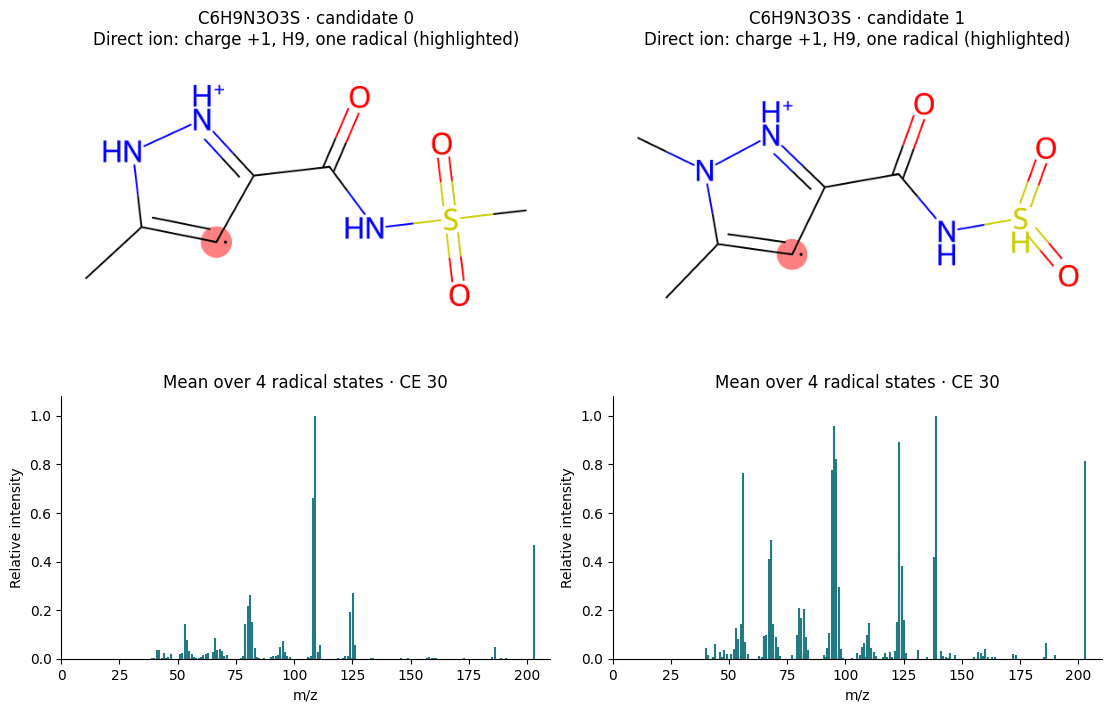

In [5]:
example_predictions = []
for row in examples:
    prepared = prepared_by_id[row["candidate_id"]]
    assert all(item["adduct"] == "[M]+" for item in prepared["inputs"])
    spectrum = predict_prepared(model, prepared).as_array()
    assert len(spectrum) and np.isfinite(spectrum).all()
    assert np.isclose(spectrum[:,1].sum(), 1)
    example_predictions.append({"candidate_id": row["candidate_id"],
        "candidate_index": row["candidate_index"], "route": prepared["route"],
        "states": prepared["states"], "spectrum": spectrum.tolist()})
    print("Candidate", row["candidate_index"], "retained states:", len(prepared["states"]),
          "predicted peaks:", len(spectrum), "charge +1 / one radical per state")

import matplotlib.pyplot as plt
from rdkit.Chem import Draw
fig, axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained",
                         gridspec_kw={"height_ratios": [1.3, 1]})
for col, item in enumerate(example_predictions):
    state = item["states"][0]
    mol = Chem.MolFromSmiles(state["ionic_smiles"])
    axes[0,col].imshow(Draw.MolToImage(mol, size=(550,320),
                                    highlightAtoms=state["radical_atom_indices"]))
    axes[0,col].axis("off")
    axes[0,col].set_title(f"C6H9N3O3S · candidate {item['candidate_index']}\n"
                           "Direct ion: charge +1, H9, one radical (highlighted)")
    peaks = np.asarray(item["spectrum"])
    axes[1,col].vlines(peaks[:,0], 0, peaks[:,1]/peaks[:,1].max(), color="#247a83")
    axes[1,col].set(xlim=(0,210), ylim=(0,1.08), xlabel="m/z", ylabel="Relative intensity",
                     title=f"Mean over {len(item['states'])} radical states · CE 30")
    axes[1,col].spines[["top","right"]].set_visible(False)
fig.savefig(LAB / "radical_gallery.png", dpi=160, bbox_inches="tight")
plt.show()

In [6]:
summary = {
    "odd_electron_candidates": len(coverage), "directly_representable": available,
    "still_fail": len(coverage)-available,
    "remaining_reasons": dict(Counter(r["reason"] for r in coverage if not r["available"])),
    "baseline_cases": len(regression),
    "all_baseline_live_exact": all(r["live_spectrum_exact"] for r in regression),
    "all_baseline_saved_exact": all(r["previous_saved_spectrum_exact"] for r in regression),
    "actual_example_candidates": len(examples), "actual_example_forward_checks": len(example_predictions),
    "max_states": MAX_STATES, "model_collision_energy": CE,
    "coverage_seconds_excluding_cached_examples": coverage_seconds,
    "checkpoint": model.checkpoint_identity,
    "production_files_unchanged": verify_production_files(),
    "recovered_accuracy_validated": False,
}
report = {"summary": summary, "coverage": coverage,
          "baseline_regression": regression, "example_predictions": example_predictions}
(LAB / "radical_results.json").write_text(json.dumps(report, indent=2) + "\n")
print(json.dumps(summary, indent=2))

{
  "odd_electron_candidates": 74,
  "directly_representable": 74,
  "still_fail": 0,
  "remaining_reasons": {},
  "baseline_cases": 9,
  "all_baseline_live_exact": true,
  "all_baseline_saved_exact": true,
  "actual_example_candidates": 2,
  "actual_example_forward_checks": 2,
  "max_states": 4,
  "model_collision_energy": 30.0,
  "coverage_seconds_excluding_cached_examples": 42.71541212499142,
  "checkpoint": {
    "ms_pred_commit": "67ba0f202305d4bed3134991dd4562fe1edb1763",
    "checkpoint_sha256": "5a47cecca707d3abd5a49c7dbac99d100aa2a586d5d4f848f1e8e35140d7db11"
  },
  "production_files_unchanged": 12,
  "recovered_accuracy_validated": false
}


## Limits and focused tests

The new route represents a real **formal +1, one-radical molecular state**, rather than the earlier neutral reference. It preserves graph/aromatic labels, formula, H, charge, and mass under the declared domain. That addresses the adapter's representation rejection.

Glacier's unchanged input builder has **no explicit radical-electron-count feature**. It still receives the radical molecule's ordinary formal-charge, H, hybridization, aromaticity and mass descriptors; this experiment does not prove it predicts radical fragmentation accurately. No recovered bag in this pilot has observed MS3, and no accuracy benchmark or training was performed.

Coverage above counts validated, featurizable states for the 74 saved odd-electron candidates. Model forwards are deliberately limited to the two requested example candidates and the nine baseline regressions. A remaining aromatic-only failure is outside this route.

Focused tests: [`recovery_lab/test_radical.py`](recovery_lab/test_radical.py). They check the two real example graphs, formula, charge, H, radical count/site, mass, exact aromatic graph, input nonmutation, native adduct semantics, opt-in/gating, state limits/ranking, MS3 independence, and baseline preparation/prediction preservation. Their lightweight model double checks routing; the live numerical regression is in this notebook.

```bash
.venv/bin/python -m pytest recovery_lab/test_radical.py -q
```

Use `predict_radical_candidate(model, candidate, collision_energy=30, allow_radical=True)` to try one candidate. Default `allow_radical=False` retains the original availability policy. Inspect `route`, `states`, `metadata`, and `spectrum`; failed preparation returns `spectrum=None`.


## Recorded outcome

* **74 / 74** previously odd-electron candidates directly representable; **0 still fail** in that saved set.
* **Both C6H9N3O3S candidate graphs:** four retained +1, one-radical states each, plus successful finite normalized model predictions.
* **9 / 9 baseline cases:** prepared states and inputs unchanged; live and previously saved spectra compare exactly equal.
* **19 focused tests passed.** All 12 monitored production files and the checkpoint remain unchanged.

The retained direct states have minimum total absolute formal charge 1 for 34 candidates, 3 for 21 candidates, and 5 for 19 candidates. Thus 40 still require additional separated formal charges within this domain. Forty searches reached the 512-chemical-state cap, and all 74 applied the four-retained-state cap. These are valid bounded representations under the declared rules, not established physical state populations or prediction-accuracy results.

The separate aromatic-only failure is still unavailable in this notebook, so combined availability is **83 / 84** for this route plus the unchanged baseline. Aromatic recovery remains a separate experiment.